In [10]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ananyaarya22/isl-data")

print("Path to dataset files:", path)

100%|██████████| 1.07G/1.07G [00:19<00:00, 57.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ananyaarya22/isl-data/versions/1


In [11]:
import os
dataset_path = path

file_list = os.listdir(dataset_path)
print(file_list)

['isl_dataset']


In [13]:
dataset_path = os.path.join(path,'isl_dataset')

file_list = os.listdir(dataset_path)
print(file_list)

['L', '2', 'T', '0', '9', '7', '1', 'W', 'C', 'O', 'N', 'J', 'H', 'R', 'X', 'S', 'Q', '3', 'D', 'P', 'M', 'G', '8', 'B', 'U', '6', 'E', 'V', 'Z', '4', 'F', 'I', 'A', '5', 'K', 'Y']


In [14]:
# Pick one class folder to inspect
sample_folder = os.path.join(dataset_path, file_list[0])

# List the contents of the sample class folder
sample_files = os.listdir(sample_folder)
print(f"Total files in '{file_list[0]}': {len(sample_files)}")
print("Sample files:", sample_files[:5])

Total files in 'L': 1000
Sample files: ['L_61.jpg', 'L_619.jpg', 'L_412.jpg', 'L_996.jpg', 'L_636.jpg']


Image shape (Height, Width, Channels): (300, 300, 3)


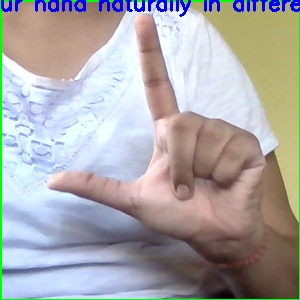

In [15]:
import cv2
from PIL import Image

# Path to a sample image
sample_img_path = os.path.join(sample_folder, sample_files[0])

# Read and check dimensions using OpenCV
img = cv2.imread(sample_img_path)
print(f"Image shape (Height, Width, Channels): {img.shape}")

# Display image
Image.open(sample_img_path)

In [17]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Standardize image dimensions for CNN input
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Augmentation and Rescaling
train_datagen = ImageDataGenerator(
    rescale=1.0/255.0,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    validation_split=0.2  # 80% Train, 20% Validation
)

# Training Data Generator
train_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

# Validation Data Generator
val_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

# Save class labels for real-time inference later
class_indices = train_generator.class_indices
labels_map = {v: k for k, v in class_indices.items()}
print("Detected Classes:", list(labels_map.values()))

Found 28811 images belonging to 36 classes.
Found 7200 images belonging to 36 classes.
Detected Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


In [18]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

NUM_CLASSES = len(class_indices)

# Base pre-trained model
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
base_model.trainable = False  # Freeze base layers initially

# Top layers for custom classification
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 64, 64,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 64, 64,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 64, 64,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 64, 64,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 64, 64,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 64, 64,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 65, 65,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 32, 32,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 32, 32,    │      2,304 │ block_1_depthwis

 Total params: 2,426,596 (9.26 MB)

 Trainable params: 168,612 (658.64 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [20]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    ModelCheckpoint('isl_mobilenet.keras', monitor='val_accuracy', save_best_only=True)
]

epochs = 5

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=epochs,
    callbacks=callbacks
)

Epoch 1/5
901/901 ━━━━━━━━━━━━━━━━━━━━ 659s 731ms/step - accuracy: 0.9585 - loss: 0.1659 - val_accuracy: 0.9636 - val_loss: 0.1122
Epoch 2/5
901/901 ━━━━━━━━━━━━━━━━━━━━ 680s 755ms/step - accuracy: 0.9813 - loss: 0.0674 - val_accuracy: 0.9712 - val_loss: 0.0931
Epoch 3/5
901/901 ━━━━━━━━━━━━━━━━━━━━ 674s 749ms/step - accuracy: 0.9848 - loss: 0.0507 - val_accuracy: 0.9750 - val_loss: 0.0827
Epoch 4/5
901/901 ━━━━━━━━━━━━━━━━━━━━ 663s 735ms/step - accuracy: 0.9856 - loss: 0.0452 - val_accuracy: 0.9812 - val_loss: 0.0639
Epoch 5/5
901/901 ━━━━━━━━━━━━━━━━━━━━ 653s 725ms/step - accuracy: 0.9874 - loss: 0.0391 - val_accuracy: 0.9751 - val_loss: 0.0864


In [21]:
import json

# Save class mapping to JSON
with open("class_indices.json", "w") as f:
    json.dump(labels_map, f)

print("Model and class mapping successfully saved!")

Model and class mapping successfully saved!


In [22]:
from google.colab import files
files.download('isl_mobilenet.keras')
files.download('class_indices.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>